# K-Means phân khúc khách hàng

    Phần Task 2 được tách riêng từ Stage2 đã ghép PCA của nhóm. Chạy lần lượt các ô từ đầu, không cần chạy notebook Stage2.

    Đầu vào PCA là `pca_features.csv` lấy từ kết quả `duanpython`. K-Means chỉ sử dụng PC1, PC2, PC3; CustomerID dùng để ghép đúng khách hàng. Dữ liệu lịch sử được dùng để so sánh với cách không giảm chiều và để mô tả cụm.

## 1 Đọc dữ liệu và ghép PC theo CustomerID

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from pathlib import Path
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

RANDOM_STATE = 42
BASE_DIR = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
RESULT_DIR = BASE_DIR / "ket_qua"
RESULT_DIR.mkdir(exist_ok=True)
FEATURES = [
    "RecencyDays", "Frequency", "MonetaryGBP", "TotalUnits",
    "AvgProductsPerInvoice", "ObservedTenureDays", "AvgOrderValueGBP"
]
PCA_FEATURES = [
    "Frequency", "MonetaryGBP", "TotalUnits", "AvgProductsPerInvoice",
    "RecencyDays", "ObservedTenureDays", "AvgOrderValueGBP"
]
LOG_COLUMNS = [
    "Frequency", "MonetaryGBP", "TotalUnits",
    "AvgProductsPerInvoice", "AvgOrderValueGBP"
]
# Biến tương lai chỉ dùng mô tả sau khi có cụm; không tham gia fit K-Means.
REG_TARGET = "Chi_tieu_90_ngay_GBP"
PC_COLUMNS = ["PC1", "PC2", "PC3"]

data = pd.read_csv(BASE_DIR / "data_khach_hang.csv")
pca_data = pd.read_csv(BASE_DIR / "pca_features.csv")
assert data["CustomerID"].is_unique and pca_data["CustomerID"].is_unique
assert set(data["CustomerID"]) == set(pca_data["CustomerID"]), "Hai tệp phải có cùng khách hàng."
# loc sắp xếp lại PC theo đúng thứ tự khách hàng của CSV gốc.
pca_aligned = pca_data.set_index("CustomerID").loc[data["CustomerID"], PC_COLUMNS]
X_pca = pca_aligned.to_numpy()
assert np.isfinite(X_pca).all(), "Dữ liệu PC thiếu hoặc không hợp lệ."
assert np.isfinite(data[FEATURES].to_numpy(dtype=float)).all()
assert (data[FEATURES] >= 0).all().all()
print("Số khách hàng:", len(data))
print("Kích thước dữ liệu PCA:", X_pca.shape)
display(data.head())
display(pca_aligned.head())

Số khách hàng: 1000
Kích thước dữ liệu PCA: (1000, 3)


,CustomerID,Frequency,MonetaryGBP,TotalUnits,AvgProductsPerInvoice,Country,Kenh_lien_he_mo_phong,RecencyDays,ObservedTenureDays,AvgOrderValueGBP,Chi_tieu_90_ngay_GBP,Mua_lai_90_ngay,RegionGroup
0,12354,1,1079.40,530,58.000000,Spain,Email,132,132,1079.400000,0.00,0,Other countries
1,12358,3,1774.04,622,17.333333,Austria,Phone,50,450,591.346667,0.00,0,Other countries
2,12363,2,552.00,408,11.500000,Unspecified,SMS,9,142,276.000000,0.00,0,Other countries
3,12365,2,641.38,174,11.000000,Cyprus,SMS,191,191,320.690000,0.00,0,Other countries
4,12370,5,3018.07,2053,29.600000,Cyprus,SMS,174,524,603.614000,739.28,1,Other countries


,PC1,PC2,PC3
CustomerID,,,
12354,0.505565,-3.045908,0.194336
12358,1.222284,-0.376677,-0.016404
12363,-0.397573,-1.053059,-1.614249
12365,-0.850635,-0.763688,-0.536342
12370,2.096434,-0.112264,0.972179


## 2 Chuẩn bị đầu vào so sánh trước khi giảm chiều

    Lấy đúng 7 cột và biến đổi log1p cho đúng 5 cột như phần PCA của nhóm, sau đó StandardScaler. Các PC đã có sẵn nên không fit lại PCA trong phần K-Means này.

In [3]:
X_log = data[PCA_FEATURES].copy()
X_log[LOG_COLUMNS] = np.log1p(X_log[LOG_COLUMNS])
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_log)
print("Dữ liệu trước khi giảm chiều:", X_scaled.shape)
print("Dữ liệu sau PCA:", X_pca.shape)

Dữ liệu trước khi giảm chiều: (1000, 7)
Dữ liệu sau PCA: (1000, 3)


## 3 Thử K từ 2 đến 10 bằng WCSS và Silhouette

In [4]:
K_RANGE = range(2, 11)
ket_qua_cum_goc = []
ket_qua_cum_pca = []

for k in K_RANGE:
    # K-Means trên 7 đặc trưng đã log1p và chuẩn hóa
    model_goc = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=20)
    nhan_goc = model_goc.fit_predict(X_scaled)
    ket_qua_cum_goc.append({
        "K": k,
        "WCSS": model_goc.inertia_,
        "Silhouette": silhouette_score(X_scaled, nhan_goc)
    })

    # K-Means trên dữ liệu PCA
    model_pca = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=20)
    nhan_pca = model_pca.fit_predict(X_pca)
    ket_qua_cum_pca.append({
        "K": k,
        "WCSS": model_pca.inertia_,
        "Silhouette": silhouette_score(X_pca, nhan_pca)
    })

scores_goc = pd.DataFrame(ket_qua_cum_goc)
scores_pca = pd.DataFrame(ket_qua_cum_pca)

print("=== K-Means trên 7 đặc trưng log + scale ===")
display(scores_goc.round(4))
print("=== K-Means trên dữ liệu PCA ===")
display(scores_pca.round(4))

=== K-Means trên 7 đặc trưng log + scale ===


,K,WCSS,Silhouette
0,2,4604.0998,0.2966
1,3,3819.7473,0.2344
2,4,3288.3051,0.2473
3,5,2898.5162,0.2224
4,6,2644.0500,0.2206
5,7,2467.7410,0.2157
6,8,2314.3022,0.2027
7,9,2206.7358,0.1912
8,10,2093.5091,0.2000


=== K-Means trên dữ liệu PCA ===


,K,WCSS,Silhouette
0,2,3764.5841,0.3375
1,3,2983.6033,0.2793
2,4,2453.6059,0.2959
3,5,2076.4923,0.2761
4,6,1829.0790,0.2785
5,7,1657.4071,0.2772
6,8,1513.4063,0.2628
7,9,1399.3750,0.2569
8,10,1301.2586,0.2518


## 4 Vẽ Elbow và Silhouette

    Đường Elbow cho thấy WCSS giảm khi tăng K. Silhouette đo mức độ gần nhau trong cụm và tách biệt giữa các cụm. Cần xem cùng hồ sơ cụm; WCSS giữa hai không gian không so sánh trực tiếp.

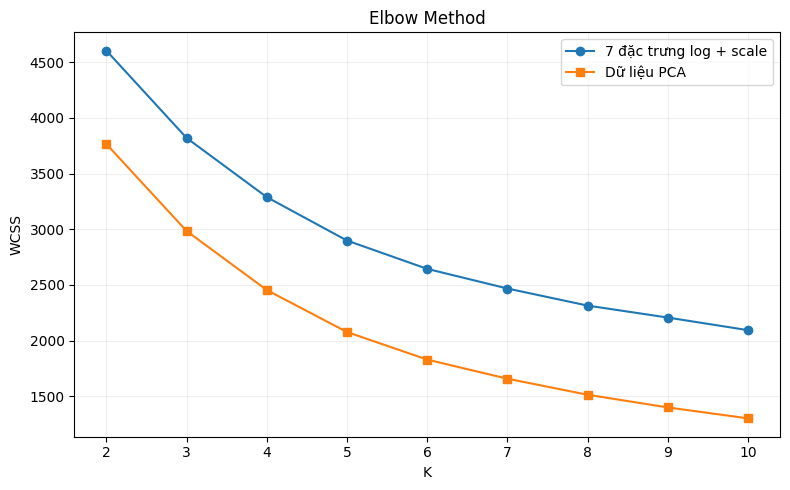

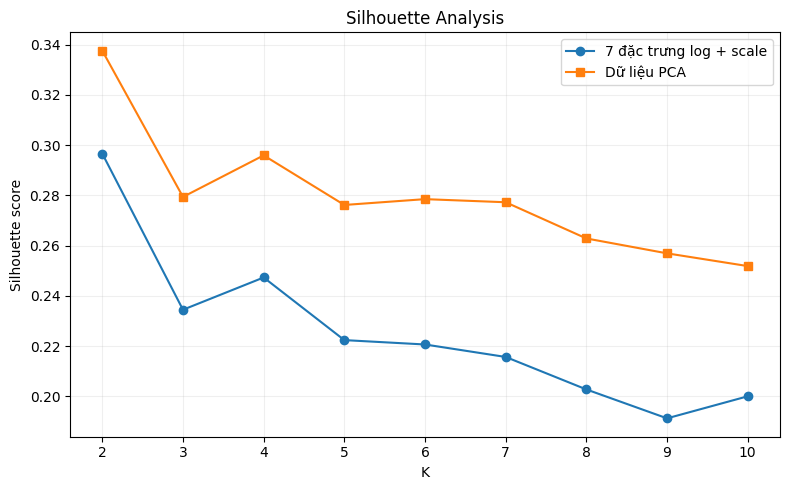

In [5]:
# Elbow: WCSS theo K
plt.figure(figsize=(8, 5))
plt.plot(scores_goc["K"], scores_goc["WCSS"], marker="o", label="7 đặc trưng log + scale")
plt.plot(scores_pca["K"], scores_pca["WCSS"], marker="s", label="Dữ liệu PCA")
plt.xlabel("K")
plt.ylabel("WCSS")
plt.title("Elbow Method")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.savefig(RESULT_DIR / "kmeans_elbow.png", dpi=150)
plt.show()

# Silhouette so sánh 7 đặc trưng log + scale và PCA
plt.figure(figsize=(8, 5))
plt.plot(scores_goc["K"], scores_goc["Silhouette"], marker="o", label="7 đặc trưng log + scale")
plt.plot(scores_pca["K"], scores_pca["Silhouette"], marker="s", label="Dữ liệu PCA")
plt.xlabel("K")
plt.ylabel("Silhouette score")
plt.title("Silhouette Analysis")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.savefig(RESULT_DIR / "kmeans_silhouette.png", dpi=150)
plt.show()

## 5 Chọn K và huấn luyện mô hình cuối

In [6]:
# Chọn K có Silhouette cao nhất ở từng cách biểu diễn dữ liệu
best_k_goc = int(scores_goc.loc[scores_goc["Silhouette"].idxmax(), "K"])
best_k_pca = int(scores_pca.loc[scores_pca["Silhouette"].idxmax(), "K"])

print("K tốt nhất - 7 đặc trưng log + scale:", best_k_goc)
print("K tốt nhất - dữ liệu PCA:", best_k_pca)

# Dùng K của PCA để tạo cột Cluster_Label cho dữ liệu chính
K = best_k_pca
kmeans_goc = KMeans(n_clusters=K, random_state=RANDOM_STATE, n_init=20)
labels_goc = kmeans_goc.fit_predict(X_scaled)
kmeans_pca = KMeans(n_clusters=K, random_state=RANDOM_STATE, n_init=20)
labels_pca = kmeans_pca.fit_predict(X_pca)

comparison_cluster = pd.DataFrame({
    "Model": ["K-Means LogScaled", "K-Means PCA"],
    "K": [K, K],
    "WCSS": [kmeans_goc.inertia_, kmeans_pca.inertia_],
    "Silhouette": [
        silhouette_score(X_scaled, labels_goc),
        silhouette_score(X_pca, labels_pca)
    ]
})
display(comparison_cluster.round(4))
print("Lưu ý: không so sánh trực tiếp WCSS giữa hai không gian có số chiều khác nhau; Silhouette cũng phụ thuộc không gian, cần xem thêm kích thước và hồ sơ cụm.")

K tốt nhất - 7 đặc trưng log + scale: 2
K tốt nhất - dữ liệu PCA: 2


,Model,K,WCSS,Silhouette
0,K-Means LogScaled,2,4604.0998,0.2966
1,K-Means PCA,2,3764.5841,0.3375


Lưu ý: không so sánh trực tiếp WCSS giữa hai không gian có số chiều khác nhau; Silhouette cũng phụ thuộc không gian, cần xem thêm kích thước và hồ sơ cụm.


## 6 Gắn nhãn và mô tả cụm bằng đơn vị gốc

    K-Means sử dụng cả 3 PC; biểu đồ PC1–PC2 chỉ minh họa phép chiếu 2D. Chi tiêu thực tế 90 ngày chỉ được tổng hợp sau phân cụm. Cluster 0 và Cluster 1 là mã cụm, không phải nhãn mua lại.

,So_khach,RecencyDays,Frequency,MonetaryGBP,TotalUnits,AvgProductsPerInvoice,ObservedTenureDays,AvgOrderValueGBP,Chi_tieu_90_ngay_GBP
Cluster_Label,,,,,,,,,
0,568,240.86,1.80,411.60,221.70,17.52,310.36,253.63,144.19
1,432,101.35,8.93,3971.15,2477.41,25.02,445.66,513.04,787.88


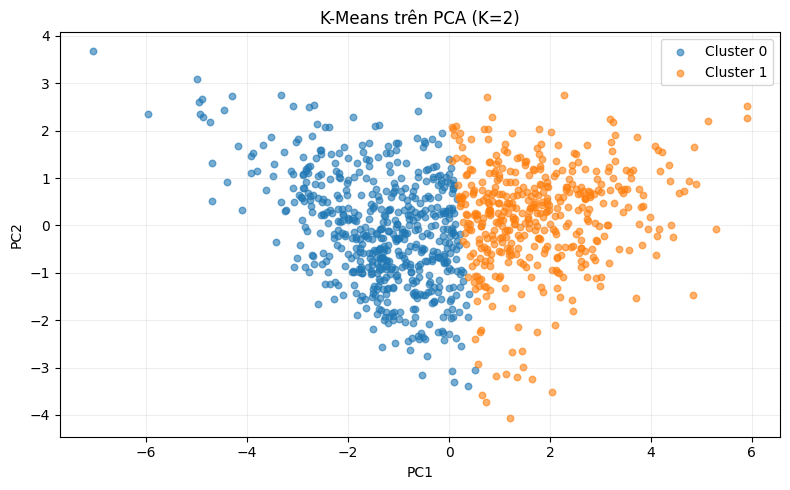

In [7]:
# Gắn nhãn cụm vào dữ liệu và xem đặc điểm trung bình từng cụm
data_stage2 = data.copy()
data_stage2["Cluster_Label"] = labels_pca

profile_cluster = data_stage2.groupby("Cluster_Label")[FEATURES + [REG_TARGET]].mean().round(2)
profile_cluster.insert(0, "So_khach", data_stage2.groupby("Cluster_Label").size())
display(profile_cluster)

plt.figure(figsize=(8, 5))
for cluster_id in sorted(data_stage2["Cluster_Label"].unique()):
    mask = data_stage2["Cluster_Label"] == cluster_id
    plt.scatter(X_pca[mask, 0], X_pca[mask, 1], s=22, alpha=0.6, label=f"Cluster {cluster_id}")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title(f"K-Means trên PCA (K={K})")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.savefig(RESULT_DIR / "kmeans_clusters.png", dpi=150)
plt.show()

## 7 Lưu kết quả riêng

    Kết quả của bộ dữ liệu này: K = 2; Silhouette trên PCA khoảng 0,3375. Cluster 0 có 568 khách, Cluster 1 có 432 khách. Xem báo cáo Word để sử dụng phần diễn giải.

In [8]:
data_stage2.to_csv(RESULT_DIR / "data_khach_hang_kmeans.csv", index=False, encoding="utf-8-sig")
scores_goc.to_csv(RESULT_DIR / "scores_logscaled.csv", index=False)
scores_pca.to_csv(RESULT_DIR / "scores_pca.csv", index=False)
comparison_cluster.to_csv(RESULT_DIR / "comparison.csv", index=False)
profile_cluster.to_csv(RESULT_DIR / "cluster_profile.csv", encoding="utf-8-sig")
joblib.dump(kmeans_pca, RESULT_DIR / "kmeans_pca.pkl")
print("Đã lưu code chạy riêng, biểu đồ, bảng kết quả và nhãn cụm tại:", RESULT_DIR)

Đã lưu code chạy riêng, biểu đồ, bảng kết quả và nhãn cụm tại: /workspace/scratch/0a80c29501d5/output/Phan_Rieng/KMeans_Rieng/ket_qua
